# 🐍 Clase 42b — De la tabla a las listas

**Curso:** 3ro medio  |  **Duración:** 80 min  |  **Plataforma:** Google Colab

---

## 🎯 Objetivo de la clase

Convertir una tabla de datos en listas de entradas y etiquetas para entrenar y evaluar un modelo con atención.

## 🔎 ¿Por qué lo veremos?

> Antes de que un modelo aprenda algo, alguien tiene que ordenar los datos para dárselos, y un dato en el lugar equivocado le enseña algo falso sin que nadie lo note. Hoy ordenamos los registros del wifi del liceo y medimos qué tan bien predice la red.

---

**Lo que ya sabes:** todo lo dictado hasta N°42 (variables, etiqueta, `DecisionTreeClassifier`, `fit()` y `predict()`) y Python hasta listas.

**Lo que aprenderás hoy:** escribir una tabla como listas, elegir qué columnas usar, separar filas para aprender y para probar, y medir qué tan bien acierta el modelo con `accuracy_score`. **Todos los datos vienen en este cuaderno** (sin archivos ni descargas) y se ejecuta de arriba hacia abajo.

### 🔧 Antes de empezar

Ejecuta la celda de abajo una sola vez: deja listos los **verificadores automáticos** que usaremos para revisar tus listas (no hace falta entenderla ni editarla).

In [ ]:
#@title 🔧 Verificador automático — ejecuta esta celda antes de empezar (no la edites)
import base64
import hashlib
import itertools
from sklearn.tree import DecisionTreeClassifier

_NOMBRES = ["dispositivos_conectados", "estudiantes_viendo_video", "horas_desde_reinicio", "temperatura_sala", "hora_del_bloque", "dia_del_mes"]
_TABLA = [[71, 0, 20, 24, 8, 7], [62, 2, 12, 29, 6, 23], [79, 2, 2, 23, 1, 23], [73, 0, 15, 19, 7, 20], [102, 9, 22, 18, 6, 4], [103, 20, 1, 23, 6, 31], [101, 17, 12, 26, 5, 29], [59, 22, 23, 30, 3, 6], [77, 7, 22, 24, 4, 4], [50, 0, 14, 30, 4, 27], [76, 0, 14, 26, 6, 28], [69, 0, 7, 24, 5, 18], [59, 0, 19, 33, 7, 21], [115, 28, 22, 20, 4, 26], [47, 2, 2, 19, 6, 21], [78, 0, 16, 29, 3, 31], [51, 0, 16, 22, 5, 3], [117, 0, 16, 30, 4, 5], [75, 22, 2, 18, 8, 24], [66, 0, 9, 27, 6, 5]]
_ETIQ = [1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0]
_G_TABLA, _G_ETIQ, _G_ACIERTOS = [[[31, 8, 24, 300, 19], [54, 16, 6, 300, 12], [59, 20, 12, 300, 24], [24, 0, 19, 300, 19], [15, 10, 20, 200, 19], [40, 15, 24, 200, 15], [44, 0, 5, 100, 4], [49, 0, 24, 300, 25], [42, 11, 2, 300, 28], [46, 16, 22, 100, 7]], [1, 1, 1, 0, 0, 1, 0, 1, 0, 1], 2]
_E1_TABLA, _E1_ETIQ, _E1_ACIERTOS = [[[62, 18, 10, 24], [50, 5, 0, 12], [43, 3, 0, 15], [30, 18, 3, 31], [32, 2, 0, 25], [17, 12, 16, 31], [19, 0, 13, 12], [15, 7, 16, 22], [24, 0, 6, 30], [60, 10, 15, 21]], [1, 1, 0, 1, 0, 1, 0, 0, 0, 1], 2]
_E2_ETIQ = [1, 1, 0, 0, 1, 0, 0, 0]
_E3_TABLA, _E3_ETIQ = [[[61, 10, 2, 23, 5, 20], [104, 0, 7, 25, 3, 10], [92, 0, 4, 23, 2, 11], [45, 23, 4, 22, 3, 21], [82, 0, 14, 21, 1, 13], [81, 0, 15, 25, 2, 12], [79, 4, 23, 18, 6, 3], [97, 19, 23, 32, 1, 25], [46, 0, 1, 21, 1, 5], [100, 0, 24, 24, 7, 16]], [0, 1, 0, 1, 0, 0, 1, 1, 0, 1]]
_E0A = [[[60, 5, 3], [95, 20, 14], [40, 0, 22]], [0, 1, 0]]


def _columnas_usadas(filas, tabla, inicio):
    """Busca qué columnas (y en qué orden) usó el estudiante: devuelve (columnas, filas que coinciden)."""
    k = len(filas[0])
    mejor, mejor_n = None, -1
    for cols in itertools.permutations(range(len(tabla[0])), k):
        n = sum(1 for i, f in enumerate(filas) if [tabla[inicio + i][c] for c in cols] == list(f))
        if n > mejor_n:
            mejor, mejor_n = cols, n
    return mejor, mejor_n


def _revisar(tabla, etiquetas, n_train, cols_esperadas=None, nombres=None):
    g = globals()
    nombres = nombres or _NOMBRES
    claves = ("entradas_train", "etiquetas_train", "entradas_test", "etiquetas_test")
    valores = [g.get(c) for c in claves]
    faltan = [c for c, v in zip(claves, valores) if not v]
    if faltan:
        print("⏳ Todavía faltan estas listas:", ", ".join(faltan))
        return None
    e_tr, y_tr, e_te, y_te = valores
    n_test = len(tabla) - n_train
    for nombre, v, n in (("entradas_train", e_tr, n_train), ("etiquetas_train", y_tr, n_train),
                         ("entradas_test", e_te, n_test), ("etiquetas_test", y_te, n_test)):
        if len(v) != n:
            print(f"⚠️ {nombre} tiene {len(v)} elementos y debería tener {n} (uno por fila).")
            print("   Pista: cuenta las filas de la tabla y revisa que no falte ninguno ni sobre uno.")
            return None
    for nombre, v in (("entradas_train", e_tr), ("entradas_test", e_te)):
        if not all(isinstance(f, (list, tuple)) and len(f) == len(e_tr[0]) for f in v):
            print(f"⚠️ En {nombre} cada fila debe ser una lista con la misma cantidad de datos.")
            print("   Pista: cada fila va entre corchetes y con una coma entre sus datos.")
            return None
    for nombre, mios, reales, inicio in (("etiquetas_train", y_tr, etiquetas[:n_train], 0),
                                         ("etiquetas_test", y_te, etiquetas[n_train:], n_train)):
        for i, (a, b) in enumerate(zip(mios, reales)):
            if a != b:
                print(f"⚠️ La etiqueta de la posición {i + 1} de {nombre} no coincide con la de la fila {inicio + i + 1} de la tabla.")
                print("   Pista: cada etiqueta debe estar en la misma posición que su fila.")
                return None
    cols, ok = _columnas_usadas(e_tr, tabla, 0)
    if ok < len(e_tr):
        i = next(j for j, f in enumerate(e_tr) if [tabla[j][c] for c in cols] != list(f))
        print(f"⚠️ El fila {i + 1} de entradas_train no coincide con la tabla.")
        print("   Pista: revisa que cada dato esté en la columna correcta y que el orden de las columnas sea el mismo en todas las filas.")
        return None
    cols_te, ok_te = _columnas_usadas(e_te, tabla, n_train)
    if cols_te != cols or ok_te < len(e_te):
        print("⚠️ entradas_test no usa las mismas columnas, en el mismo orden, que entradas_train.")
        print("   Pista: las filas de prueba deben escribirse igual que los de entrenamiento.")
        return None
    if cols_esperadas is not None and tuple(cols) != tuple(cols_esperadas):
        print("⚠️ Tus listas coinciden con la tabla, pero usaste otras columnas: ", ", ".join(nombres[c] for c in cols))
        print("   Pista: las columnas pedidas son:", ", ".join(nombres[c] for c in cols_esperadas), "(en ese orden)")
        return None
    return cols


def _aciertos(cols, tabla, etiquetas, n_train):
    m = DecisionTreeClassifier(max_depth=3, random_state=0)
    m.fit([[f[c] for c in cols] for f in tabla[:n_train]], etiquetas[:n_train])
    pred = m.predict([[f[c] for c in cols] for f in tabla[n_train:]])
    return int(sum(1 for p, y in zip(pred, etiquetas[n_train:]) if p == y))


def _cierre_accuracy(aciertos, n_test):
    ex = globals().get("exactitud")
    if ex is None:
        print("⏳ Falta calcular el accuracy y guardarlo en una variable llamada exactitud.")
    elif abs(ex - aciertos / n_test) < 1e-9:
        print("✅ Tu accuracy es el esperado.")
    else:
        print("⚠️ Tu accuracy no coincide con el esperado.")
        print("   Pista: entrena con profundidad máxima 3 y semilla 0, y compara las predicciones con etiquetas_test.")


def check_icn():
    cols = _revisar(_TABLA, _ETIQ, 16, (0, 1, 2))
    if cols is None:
        return
    print("✅ Tus listas coinciden con la tabla, fila por fila y etiqueta por etiqueta.")
    esperados = [_NOMBRES[c] for c in (0, 1, 2)]
    nv = globals().get("nombres_variables")
    if nv is None:
        print("⏳ Falta escribir nombres_variables con los nombres de tus 3 columnas.")
    elif list(nv) != esperados:
        print("⚠️ Los nombres de nombres_variables no coinciden con tus columnas, o están en otro orden.")
        print("   Pista: deben ir en el mismo orden que las columnas de tus listas:", ", ".join(esperados))
    else:
        print("✅ nombres_variables coincide con tus columnas y con su orden.")
    _cierre_accuracy(_aciertos(cols, _TABLA, _ETIQ, 16), 4)
    print("   Con solo 4 filas de test, ¿alcanza con acertar los 4 para confiar en el modelo?")


def check_guiada():
    cols = _revisar(_G_TABLA, _G_ETIQ, 8, (0, 1, 2), ["computadores_en_uso", "estudiantes_viendo_video",
                                                      "horas_desde_reinicio", "ancho_de_banda_contratado", "dia_del_mes"])
    if cols is None:
        return
    print("✅ Tus listas coinciden con la tabla del liceo vecino.")
    _cierre_accuracy(_G_ACIERTOS, 2)


def check_ej0a():
    e, y = globals().get("entradas"), globals().get("etiquetas")
    if not e or not y:
        print("⏳ Todavía faltan las listas entradas y etiquetas.")
    elif [list(f) for f in e] != _E0A[0]:
        print("⚠️ entradas no coincide con la tabla.")
        print("   Pista: una lista por fila, con los tres datos en el mismo orden de las columnas, todas dentro de otra lista.")
    elif list(y) != _E0A[1]:
        print("⚠️ etiquetas no coincide con la columna cae de la tabla.")
        print("   Pista: una etiqueta por fila, en el mismo orden de las filas.")
    else:
        print("✅ Tus listas coinciden con la tabla.")


def check_ej0b():
    p = globals().get("prediccion")
    m = globals().get("modelo")
    if p is None or m is None:
        print("⏳ Falta guardar la predicción en una variable llamada prediccion.")
    elif list(p) != list(m.predict([[88, 17, 4]])):
        print("⚠️ Tu predicción no corresponde a la fila nueva (88, 17, 4).")
        print("   Pista: una sola fila nueva va dentro de otra lista: [[...]].")
    else:
        print("✅ Predijiste la fila nueva con la forma correcta.")


def check_ej1():
    cols = _revisar(_E1_TABLA, _E1_ETIQ, 8, (0, 1, 2), ["usuarios_conectados", "notebooks_en_mesas",
                                                        "horas_desde_reinicio", "dia_del_mes"])
    if cols is None:
        return
    print("✅ Tus listas coinciden con la tabla de la biblioteca.")
    _cierre_accuracy(_E1_ACIERTOS, 2)


def check_ej2():
    et = globals().get("etiquetas")
    m = globals().get("modelo")
    if et is None:
        print("⏳ Falta la lista etiquetas.")
    elif len(et) != len(_E2_ETIQ):
        print(f"⚠️ etiquetas tiene {len(et)} elementos y hay {len(_E2_ETIQ)} filas.")
        print("   Pista: compara la tabla con tu lista, fila por fila, hasta encontrar la que falta.")
    elif list(et) != _E2_ETIQ:
        print("⚠️ Ya hay una etiqueta por fila, pero alguna quedó en una posición equivocada.")
        print("   Pista: la etiqueta que agregaste debe quedar justo en la posición de su fila, no al final.")
    elif m is None or not hasattr(m, "tree_"):
        print("⏳ Las etiquetas ya están bien. Ejecuta de nuevo la celda completa para que el modelo aprenda.")
    else:
        print("✅ Corregiste la lista: cada etiqueta está en la misma posición que su fila.")


def evaluar(e_tr, y_tr, e_te, y_te):
    """Entrena un árbol (profundidad 3, semilla 0) con train y devuelve el accuracy en test."""
    m = DecisionTreeClassifier(max_depth=3, random_state=0)
    m.fit(e_tr, y_tr)
    pred = m.predict(e_te)
    return sum(1 for p, y in zip(pred, y_te) if p == y) / len(y_te)


def check_ej3():
    cols = _revisar(_E3_TABLA, _E3_ETIQ, 8, None, ["dispositivos_conectados", "estudiantes_viendo_video",
                                                   "horas_desde_reinicio", "temperatura_sala", "hora_del_bloque", "dia_del_mes"])
    if cols is None:
        return
    print("✅ Tus listas coinciden con la tabla. Columnas que usaste:", ", ".join(
        ["dispositivos_conectados", "estudiantes_viendo_video", "horas_desde_reinicio", "temperatura_sala",
         "hora_del_bloque", "dia_del_mes"][c] for c in cols))
    print("   Ahora calcula tu accuracy y el del compañero con evaluar(...) y explica cuál conviene.")


print("Verificador listo ✅")

---

## 1️⃣ Haz Ahora

El encargado de informática del liceo quiere un sistema que le avise si el wifi se va a caer durante las clases. Registró varios datos en una tabla, donde las distintas columnas son:

- `dispositivos_conectados`: cuántos aparatos hay conectados al wifi
- `estudiantes_viendo_video`: cuántos estudiantes están viendo videos
- `horas_desde_reinicio`: cuántas horas lleva el router sin reiniciarse
- `temperatura_sala`: temperatura de la sala (°C)
- `hora_del_bloque`: bloque horario del día en que se anotó (del 1 al 8)
- `dia_del_mes`: día del mes (del 1 al 31)

y no sabe cuáles le podrían servir para resolver el problema.

1. Mirando los nombres de las 6 columnas, ¿cuáles 3 creen que más ayudan a saber si el wifi se cae?
2. ¿Cuáles son las 3 que descartaron y por qué?
3. Al final de cada registro, el encargado tiene otra columna que se llama **«¿Se cayó el wifi?»**. ¿Cómo representarían esa respuesta con una **etiqueta** binaria, en código?
4. Si el cuaderno tiene **20 filas de datos**, ¿cuántas filas de datos dejarían para entrenar el modelo y cuántas para probarlo (testearlo)?

El encargado, sabiendo que programamos, nos pide ayuda para armar ese sistema — pero antes quiere que tengamos clara la lógica.

**Mis respuestas:**

1. 
2. 
3. 
4. 

---

### 🔁 Ayer → 🔀 Hoy → ➡️ Mañana

| | Qué hacíamos |
|---|---|
| 🔁 **Ayer (N°42)** | El árbol encontró solo las preguntas que separan los días atrasados de los puntuales. **Los datos ya venían escritos.** |
| 🔀 **Hoy** | **Nosotros** escribimos los datos: pasamos la tabla del cuaderno a las listas que recibe el modelo, y probamos qué tan bien aprendió. |
| ➡️ **Mañana** | La misma receta con otro modelo: una neurona. |

**Recordemos la receta de ayer:** `modelo = DecisionTreeClassifier(...)` → `modelo.fit(entradas, etiquetas)` → `modelo.predict([[...]])`.

---

## 2️⃣ Introducción al Contenido Nuevo

Esta es la tabla de registros del liceo: **20 filas de clases**, 6 columnas y la etiqueta `cae`, que responde la pregunta del encargado: **¿se cayó el wifi?** (`1` = sí, `0` = no; el 1 significa «sí», no «bueno»). Primero, cómo vamos a usarla:

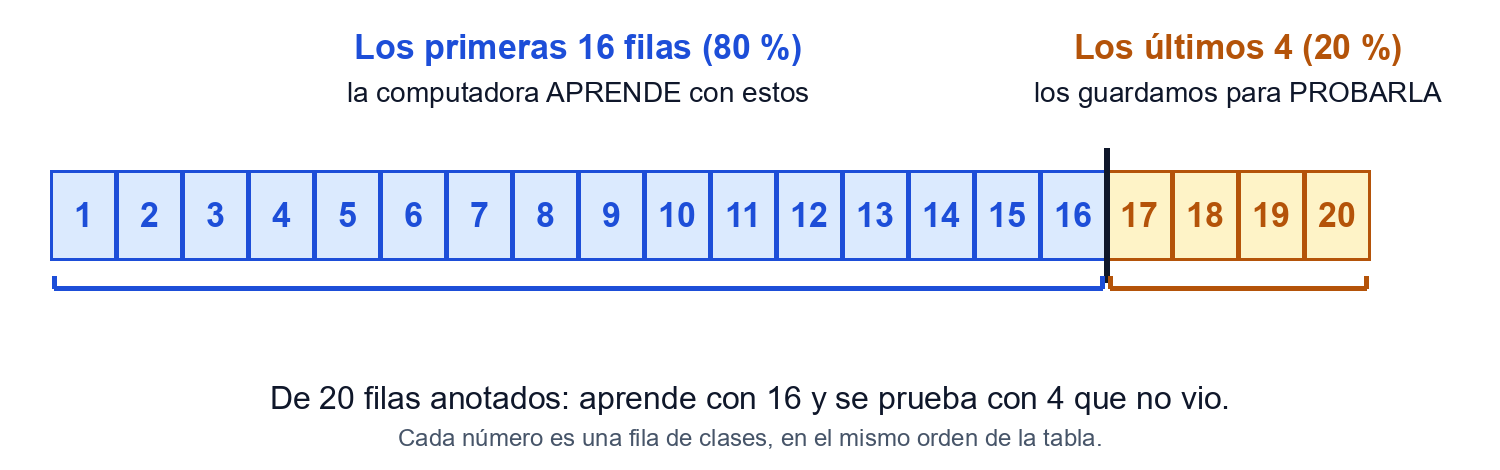

De las 20 filas, **las primeras 16** son para que la computadora **aprenda** y **las últimas 4** las guardamos para **probarla** con filas que no vio.

| Fila | `dispositivos_conectados` | `estudiantes_viendo_video` | `horas_desde_reinicio` | `temperatura_sala` | `hora_del_bloque` | `dia_del_mes` | `cae` |
|---|---|---|---|---|---|---|---|
| 1 | 71 | 0 | 20 | 24 | 8 | 7 | 1 |
| 2 | 62 | 2 | 12 | 29 | 6 | 23 | 0 |
| 3 | 79 | 2 | 2 | 23 | 1 | 23 | 0 |
| 4 | 73 | 0 | 15 | 19 | 7 | 20 | 0 |
| 5 | 102 | 9 | 22 | 18 | 6 | 4 | 1 |
| 6 | 103 | 20 | 1 | 23 | 6 | 31 | 1 |
| 7 | 101 | 17 | 12 | 26 | 5 | 29 | 1 |
| 8 | 59 | 22 | 23 | 30 | 3 | 6 | 1 |
| 9 | 77 | 7 | 22 | 24 | 4 | 4 | 1 |
| 10 | 50 | 0 | 14 | 30 | 4 | 27 | 0 |
| 11 | 76 | 0 | 14 | 26 | 6 | 28 | 0 |
| 12 | 69 | 0 | 7 | 24 | 5 | 18 | 0 |
| 13 | 59 | 0 | 19 | 33 | 7 | 21 | 0 |
| 14 | 115 | 28 | 22 | 20 | 4 | 26 | 1 |
| 15 | 47 | 2 | 2 | 19 | 6 | 21 | 0 |
| 16 | 78 | 0 | 16 | 29 | 3 | 31 | 1 |
| 17 | 51 | 0 | 16 | 22 | 5 | 3 | 0 |
| 18 | 117 | 0 | 16 | 30 | 4 | 5 | 1 |
| 19 | 75 | 22 | 2 | 18 | 8 | 24 | 1 |
| 20 | 66 | 0 | 9 | 27 | 6 | 5 | 0 |

Ahora ve concepto por concepto y escribe tú el código que falta. Todo lo que escribas queda guardado en las celdas de abajo: cada concepto usa lo que hiciste en el anterior, así que **ejecuta las celdas en orden**.

### 💡 1. Elegir las 3 columnas

Un modelo no necesita todas las columnas. Quedarnos solo con las que podrían explicar la etiqueta **ahorra procesamiento**: menos datos que anotar y que escribir, menos ruido y, en bases enormes, menos cómputo. En este ejemplo casi no se nota, pero igual debemos **justificar** la elección.

Después de revisar las 6 columnas, estas son las **3 que usaremos**:

| Columna | Qué mide |
|---|---|
| `dispositivos_conectados` | cuántos aparatos hay conectados al wifi |
| `estudiantes_viendo_video` | cuántos estudiantes están viendo videos |
| `horas_desde_reinicio` | cuántas horas lleva el router sin reiniciarse |

Quedan fuera: `temperatura_sala`, `hora_del_bloque`, `dia_del_mes`.

Así queda la tabla con las 3 columnas elegidas (de aquí vas a copiar los datos):

| Fila | `dispositivos_conectados` | `estudiantes_viendo_video` | `horas_desde_reinicio` | `cae` |
|---|---|---|---|---|
| 1 | 71 | 0 | 20 | 1 |
| 2 | 62 | 2 | 12 | 0 |
| 3 | 79 | 2 | 2 | 0 |
| 4 | 73 | 0 | 15 | 0 |
| 5 | 102 | 9 | 22 | 1 |
| 6 | 103 | 20 | 1 | 1 |
| 7 | 101 | 17 | 12 | 1 |
| 8 | 59 | 22 | 23 | 1 |
| 9 | 77 | 7 | 22 | 1 |
| 10 | 50 | 0 | 14 | 0 |
| 11 | 76 | 0 | 14 | 0 |
| 12 | 69 | 0 | 7 | 0 |
| 13 | 59 | 0 | 19 | 0 |
| 14 | 115 | 28 | 22 | 1 |
| 15 | 47 | 2 | 2 | 0 |
| 16 | 78 | 0 | 16 | 1 |
| 17 | 51 | 0 | 16 | 0 |
| 18 | 117 | 0 | 16 | 1 |
| 19 | 75 | 22 | 2 | 1 |
| 20 | 66 | 0 | 9 | 0 |

> **Idea clave:** el modelo no necesita todas las columnas: usamos las que podrían explicar la etiqueta y dejamos fuera las que no, y lo justificamos.

✍️ **Escribe tu justificación** (no es código): ¿por qué esas 3 sí y las otras 3 no?

**Mi justificación:**

Elegimos ___ porque ...

Dejamos fuera ___ porque ...

### 💡 2. Una fila es una lista

Una fila de la tabla se escribe como una **lista**: los datos van entre corchetes y cada **coma** separa una columna. Por ejemplo, la **fila 1** (71 dispositivos conectados, 0 estudiantes viendo video y 20 horas desde el reinicio) se escribe `[71, 0, 20]`. El **orden** importa: la primera posición siempre es `dispositivos_conectados`, la segunda `estudiantes_viendo_video` y la tercera `horas_desde_reinicio`, en todas las filas.

> **Idea clave:** una fila se escribe `[dato1, dato2, dato3]`: cada coma separa una columna y el **orden** es siempre el mismo.

✍️ **Escríbelo tú:** escribe la **fila 2** como una lista con las 3 columnas, en ese orden, y guárdala en una variable llamada `fila_2`.

In [ ]:
# Fila 2: dispositivos_conectados, estudiantes_viendo_video, horas_desde_reinicio
fila_2 = [ ]

### 💡 3. La tabla: filas separadas por coma, dentro de otro corchete

Para armar la tabla, se **separan las filas con comas** y se **envuelven en otro par de corchetes**: una lista de filas. Las **etiquetas** van en su propia lista, **en el mismo orden** que las filas: la primera etiqueta responde «¿se cayó el wifi?» para la primera fila (`1` = sí, `0` = no), y así.

> **Idea clave:** la tabla es varias filas separadas por coma y envueltas en otro corchete; las etiquetas (1 = sí, 0 = no) van en otra lista, en el mismo orden.

✍️ **Escríbelo tú:** completa `entradas_train` con las **primeras 16 filas** (una fila por línea) y escribe `etiquetas_train` con sus 16 resultados, en el mismo orden.

In [ ]:
# Las primeras 16 filas, una fila por línea
entradas_train = [
    [71, 0, 20],   # fila 1
    fila_2,       # ← la fila 2 ya está lista
    # escribe aquí las filas 3 a 16
]

# Los 16 resultados, en el mismo orden (1 = sí se cayó, 0 = no)
etiquetas_train = [
]

### 💡 4. Las 4 filas que guardamos para probar

El 80 % aprende; el 20 % se guarda aparte para saber si la computadora funciona con filas que **no vio**. Se escriben igual que las anteriores, con **las mismas 3 columnas y en el mismo orden**.

> **Idea clave:** con el 80 % la computadora aprende (train); el 20 % lo guardamos aparte para probarla (test).

✍️ **Escríbelo tú:** escribe `entradas_test` y `etiquetas_test` con las **últimas 4 filas** (17 a 20).

In [ ]:
# Las últimas 4 filas (17 a 20), con las mismas 3 columnas
entradas_test = [
]

etiquetas_test = [
]

### 💡 5. La receta: crear → fit → predict

Es la receta de ayer, pero ahora con **tus listas**: se entrena con `train` y se le pide `predict` sobre el `test`. Como `entradas_test` ya es una tabla, el modelo entrega **una predicción por fila**.

**¿Qué es `max_depth`?** Es cuánto le dejamos **«pensar»** al computador: el máximo de preguntas sí/no seguidas que puede hacer el árbol. Podría ser cualquier número, pero **mientras menos, mejor si los resultados no cambian**, porque es menos procesamiento.

**¿Y `random_state=0`?** Es una semilla: hace que a todos nos resulte el mismo árbol.

> **Idea clave:** `max_depth` es cuánto le dejamos pensar al árbol: mientras menos, mejor, siempre que los resultados no cambien.

✍️ **Escríbelo tú:** entrena el árbol con `entradas_train` y `etiquetas_train`, y guarda en `predicciones` lo que predice para `entradas_test`.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

modelo = DecisionTreeClassifier(max_depth=3, random_state=0)

# Entrena con train y predice el test

<details><summary>❓ ¿Cómo cambian los resultados si variamos <code>max_depth</code>?</summary>

Cambia `max_depth` a 1, 2 y 4 en la celda de arriba y vuelve a ejecutar. Con nuestras filas de entrenamiento:

- Con **1** o **2** el árbol todavía se equivoca en el entrenamiento (en 2 y en 1 de las 16 filas).
- Con **3** acierta todas las filas de entrenamiento.
- Con **4** o más queda **igual que con 3**: no necesita más preguntas. Pensar de más no mejora nada.

</details>

### 💡 6. Revisar

Al revisar hacemos dos cosas:

1. **Leer el árbol:** `export_text(modelo, feature_names=nombres_variables)` muestra las preguntas que aprendió. `nombres_variables` son los nombres de las columnas (*features*), **en el mismo orden** que en tus listas.
2. **Ver la precisión (accuracy):** `accuracy_score(etiquetas_test, predicciones)` compara las predicciones con lo que pasó de verdad: aciertos ÷ total.

✍️ **Escríbelo tú:** escribe `nombres_variables` y muestra el árbol; luego calcula el accuracy en una variable llamada `exactitud` y muéstralo con una etiqueta clara.

In [ ]:
from sklearn.tree import export_text
from sklearn.metrics import accuracy_score

# 1. Leer el árbol: los nombres van en el MISMO orden que las columnas de tus listas
nombres_variables = [ ]

# 2. Ver la precisión: usa predicciones y etiquetas_test

#### 🔍 Revisa tu trabajo

Ejecuta la celda: revisa que tus listas coincidan con la tabla, que los nombres estén en orden y que tu accuracy sea el esperado.

In [ ]:
check_icn()

#### ✅ Verificamos lo aprendido

El colega le pregunta a dos personas del curso:

- ¿Para qué guardamos 4 filas aparte?
- ¿Qué cambia si una etiqueta queda en otra posición?

### 📌 Entonces, ¿qué debe quedar claro en tu cuaderno?

| Concepto | Cómo se escribe |
|---|---|
| Columnas elegidas | solo las que podrían explicar la etiqueta, y las justificamos |
| Una fila | `[dato1, dato2, dato3]` |
| La tabla | `[[...], [...], [...]]`: filas separadas por coma, dentro de otro corchete |
| Las etiquetas | otra lista (1 = sí, 0 = no), en el mismo orden que las filas |
| Train y test | primeras 16 filas → `entradas_train` / `etiquetas_train`; últimas 4 filas → `entradas_test` / `etiquetas_test` |
| `max_depth` | cuánto le dejamos pensar al árbol: el menor valor que no empeora los resultados |
| La receta | `modelo.fit(entradas_train, etiquetas_train)` → `modelo.predict(entradas_test)` |
| Revisar | `export_text(modelo, feature_names=nombres_variables)` y `accuracy_score(etiquetas_test, predicciones)` |

#### 🎞️ Resumen animado

Para repasar la etiqueta, las columnas elegidas, cómo pasar de la tabla a las listas, el 80 / 20, `max_depth` y el accuracy, mira las slides animadas: [https://clases-ia-mario-bertero.vercel.app/clase-42b/](https://clases-ia-mario-bertero.vercel.app/clase-42b/)

#### ⚠️ Errores típicos a evitar

| Error | Qué ocurre | Cómo corregirlo |
|---|---|---|
| Cambiar el orden de las columnas entre una fila y otra | El modelo aprende algo falso, sin dar error | Usar siempre las mismas columnas en el mismo orden |
| Olvidar una etiqueta o repetirla | `ValueError`: distinta cantidad de entradas y etiquetas | Contar: una etiqueta por cada fila |
| `modelo.predict([88, 17, 4])` | `ValueError`: `predict()` espera una tabla | Poner la fila dentro de otra lista: `[[88, 17, 4]]` |
| `nombres_variables` en otro orden que las columnas | El árbol impreso habla de la columna equivocada | Escribir los nombres en el mismo orden que las columnas de las listas |
| Mirar el test mientras se elige el modelo | El accuracy deja de ser una prueba de verdad | Elegir con el train y mirar el test al final |
| Creer que 4 de 4 prueba que el modelo es bueno | Se confía con muy poca evidencia | Probar con más filas antes de confiar |

---

## 3️⃣ Práctica Guiada

Este es **el ejercicio de la clase**: lo hacemos todos, y al final revisamos uno entre todos.

### 🎯 El liceo vecino: ¿se caerá su wifi?

El liceo vecino también quiere anticipar si su wifi se cae. Su encargada de informática anotó **10 filas** en una tabla de 5 columnas y nos pide trabajar solo con **las tres primeras**. Como son 10 filas, la computadora aprende con las **primeras 8 filas** y se prueba con las **últimas 2**. Antes de confiar, quiere que revisemos si ese resultado alcanza.

| Fila | `computadores_en_uso` | `estudiantes_viendo_video` | `horas_desde_reinicio` | `ancho_de_banda_contratado` | `dia_del_mes` | `cae` |
|---|---|---|---|---|---|---|
| 1 | 31 | 8 | 24 | 300 | 19 | 1 |
| 2 | 54 | 16 | 6 | 300 | 12 | 1 |
| 3 | 59 | 20 | 12 | 300 | 24 | 1 |
| 4 | 24 | 0 | 19 | 300 | 19 | 0 |
| 5 | 15 | 10 | 20 | 200 | 19 | 0 |
| 6 | 40 | 15 | 24 | 200 | 15 | 1 |
| 7 | 44 | 0 | 5 | 100 | 4 | 0 |
| 8 | 49 | 0 | 24 | 300 | 25 | 1 |
| 9 | 42 | 11 | 2 | 300 | 28 | 0 |
| 10 | 46 | 16 | 22 | 100 | 7 | 1 |

**El programa debe:**

- **Escribir** las listas `entradas_train` y `etiquetas_train` (8 filas) y `entradas_test` y `etiquetas_test` (2 filas), con las tres columnas pedidas.
- **Entrenar** un árbol (profundidad máxima 3, semilla 0) con las 8 filas y **predecir** los 2 de prueba.
- **Calcular** el accuracy en una variable llamada `exactitud` y **mostrar** las predicciones, las etiquetas reales y el accuracy con una etiqueta clara.
- **Escribir**, en un comentario, si con solo 2 filas de prueba basta para confiar.

<details><summary>💡 Pista 1 — una fila, una lista</summary>

Cada fila son **tres** datos entre corchetes, en el mismo orden de las columnas; las filas van separadas por coma, dentro de otro corchete.

</details>

<details><summary>💡 Pista 2 — cada etiqueta con su fila</summary>

La primera etiqueta es la de la primera fila. Revisa que `entradas_train` y `etiquetas_train` tengan la misma cantidad de elementos.

</details>

📤 <em>El programa imprime:</em>

<pre>Predicciones de las 2 filas de prueba: [0 1]
Etiquetas reales: [0, 1]
Accuracy en el test: 1.0</pre>

In [ ]:
# Tu programa
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [ ]:
check_guiada()

---

## 🎫 Ticket de Salida

Las preguntas **se proyectan en la tele**: no están en este cuaderno. Mira cada pregunta y **decide tu respuesta en silencio**; cuando termine la última, abre el formulario, escribe tu nombre y marca tus alternativas.

👉 **Formulario del Ticket de Salida:** [https://forms.gle/sjRpbgmQzrpkEBsH9](https://forms.gle/sjRpbgmQzrpkEBsH9)

En «Tema de la clase de hoy» escribe: **De la tabla a las listas**.

---

## 🎯 Cierre

**Objetivo de la clase**

Convertir una tabla de datos en listas de entradas y etiquetas para entrenar y evaluar un modelo con atención.

---

**Reflexiona antes de irte** (las comentamos a viva voz):

1. ¿Qué tan seguro/a te sientes pasando una tabla a listas y entrenando y evaluando un modelo, donde 1 es "no entendí nada" y 5 es "puedo explicárselo a otro"?

2. ¿En qué momento de hoy tuvimos que **poner atención** para no cambiar un dato de lugar?

3. ¿Qué parte del orden de los datos revisamos con cuidado y cuál habríamos dejado pasar?

👀 **Lo que viene:** mañana usamos la misma receta con otro modelo: una **neurona**.

### 📝 Mis respuestas

*(haz doble click para editar y escribir tus respuestas)*

1. 

2. 

3. 

---

---

## 4️⃣ Ejercicios extra

Para seguir practicando en casa o si terminas antes. Cada uno trae pistas y, después, un verificador que te dice ✅ si vas bien. No tienen nota.

### 🎯 Ejercicio 0a — Práctica directa: de la tabla a las listas

Esta es la tabla de 3 filas del wifi:

| Fila | `dispositivos_conectados` | `estudiantes_viendo_video` | `horas_desde_reinicio` | `cae` |
|---|---|---|---|---|
| 1 | 60 | 5 | 3 | 0 |
| 2 | 95 | 20 | 14 | 1 |
| 3 | 40 | 0 | 22 | 0 |

**El programa debe:**

- Escribir `entradas` con las 3 filas (una lista por fila, con los tres datos en el orden de las columnas, todas dentro de otra lista).
- Escribir `etiquetas` con sus 3 resultados, en el mismo orden.
- Imprimir ambas listas con una etiqueta.

📤 <em>El programa imprime:</em>

<pre>entradas: [[60, 5, 3], [95, 20, 14], [40, 0, 22]]
etiquetas: [0, 1, 0]</pre>

In [ ]:
# Tu solución del Ejercicio 0a

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej0a()

### 🎯 Ejercicio 0b — Práctica directa: predecir una sola fila

La celda de abajo ya trae un modelo entrenado.

**El programa debe:**

- Preguntar al modelo por **una sola** fila nueva: 88 dispositivos, 17 estudiantes viendo video y 4 horas desde el reinicio.
- Guardar la predicción en una variable llamada `prediccion` e imprimirla con una etiqueta.

📤 <em>El programa imprime:</em>

<pre>Predicción para la fila nueva (1 = se cae, 0 = aguanta): [0]</pre>

In [ ]:
# Tu solución del Ejercicio 0b
from sklearn.tree import DecisionTreeClassifier

entradas = [[60, 5, 3],
    [95, 20, 14],
    [40, 0, 22],
    [110, 2, 8],
    [30, 12, 5],
    [85, 0, 18]]
etiquetas = [0, 1, 0, 1, 1, 0]

modelo = DecisionTreeClassifier(max_depth=2, random_state=0)
modelo.fit(entradas, etiquetas)

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej0b()

### 🎯 Ejercicio 1 — Biblioteca del liceo: ¿se cae la red en la biblioteca?

En la biblioteca del liceo, el encargado anotó 10 filas de datos en una tabla de 4 columnas y nos pide trabajar con **las tres primeras**. Quiere saber qué tan bien un árbol predice si la red se cae, aprendiendo con las primeras 8 filas y probando con las últimas 2.

| Fila | `usuarios_conectados` | `notebooks_en_mesas` | `horas_desde_reinicio` | `dia_del_mes` | `cae` |
|---|---|---|---|---|---|
| 1 | 62 | 18 | 10 | 24 | 1 |
| 2 | 50 | 5 | 0 | 12 | 1 |
| 3 | 43 | 3 | 0 | 15 | 0 |
| 4 | 30 | 18 | 3 | 31 | 1 |
| 5 | 32 | 2 | 0 | 25 | 0 |
| 6 | 17 | 12 | 16 | 31 | 1 |
| 7 | 19 | 0 | 13 | 12 | 0 |
| 8 | 15 | 7 | 16 | 22 | 0 |
| 9 | 24 | 0 | 6 | 30 | 0 |
| 10 | 60 | 10 | 15 | 21 | 1 |

**El programa debe:**

- **Escribir** las cuatro listas (train de 8 filas y test de 2) con las tres columnas pedidas.
- **Entrenar** un árbol (profundidad máxima 3, semilla 0), **predecir** el test y guardar el accuracy en `exactitud`.
- **Mostrar** las predicciones y el accuracy con etiquetas claras.

<details><summary>💡 Pista 1 — las columnas</summary>

Son tres datos por fila: usuarios conectados, notebooks en mesas y horas desde el reinicio. La cuarta columna se deja fuera.

</details>

<details><summary>💡 Pista 2 — el orden de las filas</summary>

Las primeras 8 filas van en `train` y las últimas 2 en `test`, en el mismo orden de la tabla.

</details>

📤 <em>El programa imprime:</em>

<pre>Predicciones del test: [0 1]
Accuracy en el test: 1.0</pre>

In [ ]:
# Tu solución del Ejercicio 1
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# ── Escribe tu programa desde aquí ──

In [ ]:
check_ej1()

### 🎯 Ejercicio 2 — Sala de computación: la etiqueta que falta

El profesor de computación anotó 8 filas y escribió las listas a mano, pero al entrenar el programa se cae con un error. Alguien se saltó una etiqueta. Hay que encontrar cuál falta y arreglar la lista, sin tocar las entradas.

| Fila | `equipos_encendidos` | `estudiantes_viendo_video` | `horas_desde_reinicio` | `cae` |
|---|---|---|---|---|
| 1 | 36 | 7 | 2 | 1 |
| 2 | 29 | 14 | 21 | 1 |
| 3 | 25 | 9 | 0 | 0 |
| 4 | 18 | 2 | 13 | 0 |
| 5 | 19 | 12 | 2 | 1 |
| 6 | 11 | 8 | 7 | 0 |
| 7 | 12 | 9 | 12 | 0 |
| 8 | 10 | 0 | 10 | 0 |

**El programa debe:**

- **Comparar** la tabla con la lista `etiquetas` hasta encontrar qué etiqueta falta.
- **Corregir** `etiquetas` para que cada etiqueta quede en la misma posición que su fila.
- **Ejecutar** de nuevo la celda: el modelo debe aprender sin errores.

<details><summary>💡 Pista 1 — cuántas son</summary>

Hay 8 filas: cuenta cuántas etiquetas tiene la lista.

</details>

<details><summary>💡 Pista 2 — dónde falta</summary>

Recorre la tabla y tu lista a la vez; la primera posición donde no coinciden marca la etiqueta que falta.

</details>

📤 <em>El programa imprime:</em>

<pre>El modelo ya aprendió de 8 filas</pre>

In [ ]:
# Tu solución del Ejercicio 2
from sklearn.tree import DecisionTreeClassifier

entradas = [[36, 7, 2],
    [29, 14, 21],
    [25, 9, 0],
    [18, 2, 13],
    [19, 12, 2],
    [11, 8, 7],
    [12, 9, 12],
    [10, 0, 10]]
etiquetas = [1, 1, 0, 0, 0, 0, 0]   # ← a esta lista le falta una etiqueta

modelo = DecisionTreeClassifier(max_depth=3, random_state=0)
modelo.fit(entradas, etiquetas)
print("El modelo ya aprendió de", len(entradas), "filas")

In [ ]:
check_ej2()

### 🎯 Ejercicio 3 — Sala de actos: ¿qué columnas conviene usar?

El liceo prepara un evento en la sala de actos y quiere saber si el wifi se caerá. La tabla trae **6 columnas** y 10 filas. Un compañero ya probó con tres columnas (`temperatura_sala`, `hora_del_bloque` y `dia_del_mes`). Hay que elegir **tu propio trío con criterio**, compararlo con el de tu compañero y decidir cuál conviene.

| Fila | `dispositivos_conectados` | `estudiantes_viendo_video` | `horas_desde_reinicio` | `temperatura_sala` | `hora_del_bloque` | `dia_del_mes` | `cae` |
|---|---|---|---|---|---|---|---|
| 1 | 61 | 10 | 2 | 23 | 5 | 20 | 0 |
| 2 | 104 | 0 | 7 | 25 | 3 | 10 | 1 |
| 3 | 92 | 0 | 4 | 23 | 2 | 11 | 0 |
| 4 | 45 | 23 | 4 | 22 | 3 | 21 | 1 |
| 5 | 82 | 0 | 14 | 21 | 1 | 13 | 0 |
| 6 | 81 | 0 | 15 | 25 | 2 | 12 | 0 |
| 7 | 79 | 4 | 23 | 18 | 6 | 3 | 1 |
| 8 | 97 | 19 | 23 | 32 | 1 | 25 | 1 |
| 9 | 46 | 0 | 1 | 21 | 1 | 5 | 0 |
| 10 | 100 | 0 | 24 | 24 | 7 | 16 | 1 |

**El programa debe:**

- **Escribir** las listas train (8 filas) y test (2 filas) con tus 3 columnas.
- **Calcular** tu accuracy y el del compañero con la función `evaluar(...)`, que ya viene preparada.
- **Explicar por escrito** cuál trío conviene y por qué; recuerda que con solo 2 filas de prueba una diferencia pequeña prueba poco.

<details><summary>💡 Pista 1 — elegir</summary>

Mira los nombres de las columnas: ¿cuáles podrían explicar que el wifi se caiga?

</details>

<details><summary>💡 Pista 2 — evaluar</summary>

`evaluar(entradas_train, etiquetas_train, entradas_test, etiquetas_test)` devuelve el accuracy; úsala con tus listas y con las del compañero.

</details>

📤 <em>El programa imprime:</em>

<pre>Accuracy de mi trío: …
Accuracy del trío del compañero: …</pre>

*(Tus números dependen de las columnas que elijas.)*

In [ ]:
# Tu solución del Ejercicio 3
# Las listas del compañero (temperatura_sala, hora_del_bloque, dia_del_mes) ya están escritas:
entradas_train_companero = [[23, 5, 20],
    [25, 3, 10],
    [23, 2, 11],
    [22, 3, 21],
    [21, 1, 13],
    [25, 2, 12],
    [18, 6, 3],
    [32, 1, 25]]
etiquetas_train_companero = [0, 1, 0, 1, 0, 0, 1, 1]

entradas_test_companero = [[21, 1, 5],
    [24, 7, 16]]
etiquetas_test_companero = [0, 1]

# ── Escribe tu programa desde aquí ──

✍️ **Mi explicación:** *¿Qué trío elegí y por qué? ¿Cuál conviene, el mío o el del compañero? ¿Alcanza el test para estar seguros?* ...

In [ ]:
check_ej3()

### 🎯 Ejercicio 4 — Desafío: un dato mal anotado

Imagina que, al pasar la tabla a listas, **un solo dato** del test se anotó mal: el primer dato de la primera fila de `entradas_test` quedó valiendo **100** en vez de su valor real. Con tu trío del Ejercicio 3, vuelve a calcular el accuracy con `evaluar` y compara.

**El programa debe:**

- **Cambiar** ese dato en `entradas_test`.
- **Calcular** de nuevo tu accuracy y mostrarlo con una etiqueta.
- **Escribir** si cambió tu conclusión y qué dice eso de probar con tan pocos filas y de revisar bien los datos.

<details><summary>💡 Pista 1 — cambiar un dato de una lista</summary>

`entradas_test[0][0] = 100` cambia el primer dato de la primera fila.

</details>

📤 <em>El programa imprime:</em> el accuracy de tu trío con el dato mal anotado.

In [ ]:
# Tu solución del Ejercicio 4

# ── Escribe tu programa desde aquí ──

✍️ **Mi conclusión:** ...